# Extra (puntos extras) — Integración avanzada: Romberg, Gauss-Quad y Simpson 3/8

**Fuente:** `Integracion.pdf, sección *Extra*: *"Por puntos extras y sin
límite de entrega: buscar uno de estos métodos e implementarlo al problema del cohete"*.

Se implementan los **tres** métodos y se comparan entre sí y con la regla de Simpson 1/3 sobre

$$I = \int_{8}^{30} \left[2000\,\ln\!\left(\frac{140000}{140000 - 2100\,t}\right) - 9.8\,t\right]dt$$

cuya solución exacta es conocida (antiderivada analítica, ver tarea 01).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

m0, mdot, ve, g = 140000.0, 2100.0, 2000.0, 9.8
t0, tf = 8.0, 30.0

def f(t):
    return ve*np.log(m0/(m0 - mdot*t)) - g*t

def F_antiderivada(t):
    u = m0 - mdot*t
    return -(ve/mdot)*(u*np.log(m0/u) + u) - 0.5*g*t**2

I_exacta = F_antiderivada(tf) - F_antiderivada(t0)
print(f"Integral exacta (antiderivada analítica): I = {I_exacta:.10f} m")

Integral exacta (antiderivada analítica): I = 11061.3355350810 m


## 1) Integración de Romberg

Combina la regla del trapecio con **extrapolación de Richardson**:
$R_{k,j} = R_{k,j-1} + \dfrac{R_{k,j-1} - R_{k-1,j-1}}{4^j - 1}$, refinando a la vez $h$ y el orden
de precisión. Se detiene con el criterio de error relativo aproximado (estilo Scarborough).

In [2]:
def romberg(f, a, b, es=1e-10, kmax=12):
    # Romberg, paro por error relativo. devuelve (I, tabla, n_evals)
    Tab = np.full((kmax, kmax), np.nan)
    h = b - a
    Tab[0, 0] = h/2*(f(a) + f(b))
    neval = 2
    for k in range(1, kmax):
        hk = h/2**k
        suma = sum(f(a + (2*i - 1)*hk) for i in range(1, 2**(k - 1) + 1))
        neval += 2**(k - 1)
        Tab[k, 0] = 0.5*Tab[k - 1, 0] + hk*suma
        for j in range(1, k + 1):
            Tab[k, j] = Tab[k, j - 1] + (Tab[k, j - 1] - Tab[k - 1, j - 1])/(4**j - 1)
        ea = abs((Tab[k, k] - Tab[k - 1, k - 1])/Tab[k, k])*100
        if ea < es:
            return Tab[k, k], Tab[:k + 1, :k + 1], neval
    return Tab[-1, -1], Tab, neval

I_rom, tabla, neval_rom = romberg(f, t0, tf)
print("Tabla de Romberg (filas: refinamiento h/2^k; columnas: extrapolación de Richardson):")
niv = tabla.shape[0]
print("         " + "".join([f"{'O(h^' + str(2*(j+1)) + ')':>16}" for j in range(niv)]))
for k in range(niv):
    fila = ""
    for j in range(niv):
        fila += f"{tabla[k, j]:>16.8f}" if j <= k else " " * 16
    print(f"h/2^{k}: {fila}")
print(f"\nI_Romberg = {I_rom:.10f} m   |  error = {abs(I_rom - I_exacta):.2e}  |  evaluaciones de f: {neval_rom}")

Tabla de Romberg (filas: refinamiento h/2^k; columnas: extrapolación de Richardson):
                   O(h^2)          O(h^4)          O(h^6)          O(h^8)         O(h^10)         O(h^12)         O(h^14)
h/2^0:   11868.34818984                                                                                                
h/2^1:   11266.37429326  11065.71632773                                                                                
h/2^2:   11112.82067637  11061.63613741  11061.36412472                                                                
h/2^3:   11074.22129766  11061.35483809  11061.33608480  11061.33563972                                                
h/2^4:   11064.55788699  11061.33675010  11061.33554424  11061.33553566  11061.33553525                                
h/2^5:   11062.14118012  11061.33561116  11061.33553523  11061.33553508  11061.33553508  11061.33553508                
h/2^6:   11061.53694991  11061.33553984  11061.33553508  11061.33553508  

## 2) Regla de Simpson 3/8 compuesta

$$I \approx \frac{3h}{8}\left[f_0 + 3\!\!\sum_{i \not\equiv 0 \pmod 3}\!\! f_i + 2\!\!\sum_{i \equiv 0 \pmod 3}^{n-3}\!\! f_i + f_n\right], \qquad h = \frac{b-a}{n},\ n \equiv 0 \pmod 3$$

In [3]:
def simpson_38(f, a, b, n):
    # Simpson 3/8 compuesta, n múltiplo de 3
    if n % 3 != 0:
        raise ValueError("n debe ser múltiplo de 3")
    h = (b - a)/n
    t = a + h*np.arange(n + 1)
    pesos = np.ones(n + 1)
    pesos[1:-1][np.arange(1, n) % 3 != 0] = 3.0
    pesos[1:-1][np.arange(1, n) % 3 == 0] = 2.0
    return 3*h/8*np.sum(pesos*f(t))

for n in [3, 6, 12, 24, 48, 96]:
    I38 = simpson_38(f, t0, tf, n)
    print(f"n = {n:>3}:  I = {I38:.10f}  |  error = {abs(I38 - I_exacta):.3e}")

n =   3:  I = 11063.3104810455  |  error = 1.975e+00
n =   6:  I = 11061.4696772972  |  error = 1.341e-01
n =  12:  I = 11061.3441232325  |  error = 8.588e-03
n =  24:  I = 11061.3360752349  |  error = 5.402e-04
n =  48:  I = 11061.3355688945  |  error = 3.381e-05
n =  96:  I = 11061.3355371952  |  error = 2.114e-06


## 3) Cuadratura Gauss-Legendre compuesta (3 puntos por panel)

En cada panel se mapean los nodos de Legendre $\xi = \pm\sqrt{3/5},\ 0$ con pesos
$5/9,\ 8/9,\ 5/9$; con 3 nodos la regla es exacta para polinomios de grado $\le 5$
(error local $O(h^6)$).

In [4]:
def gauss_legendre_compuesta(f, a, b, n_paneles):
    # Gauss-Legendre de 3 puntos, panel por panel
    xi_g = np.array([-np.sqrt(3/5), 0.0, np.sqrt(3/5)])
    w_g  = np.array([5/9, 8/9, 5/9])
    bordes = np.linspace(a, b, n_paneles + 1)
    I = 0.0
    for pa, pb in zip(bordes[:-1], bordes[1:]):
        c, d = (pb + pa)/2, (pb - pa)/2
        I += d*np.sum(w_g*f(c + d*xi_g))
    return I

for n in [1, 2, 4, 8, 16, 32]:
    IG = gauss_legendre_compuesta(f, t0, tf, n)
    print(f"paneles = {n:>3} ({3*n:>3} evaluaciones):  I = {IG:.10f}  |  error = {abs(IG - I_exacta):.3e}")

paneles =   1 (  3 evaluaciones):  I = 11061.3083947874  |  error = 2.714e-02
paneles =   2 (  6 evaluaciones):  I = 11061.3350090592  |  error = 5.260e-04
paneles =   4 ( 12 evaluaciones):  I = 11061.3355262977  |  error = 8.783e-06
paneles =   8 ( 24 evaluaciones):  I = 11061.3355349413  |  error = 1.397e-07
paneles =  16 ( 48 evaluaciones):  I = 11061.3355350788  |  error = 2.226e-09
paneles =  32 ( 96 evaluaciones):  I = 11061.3355350810  |  error = 6.912e-11


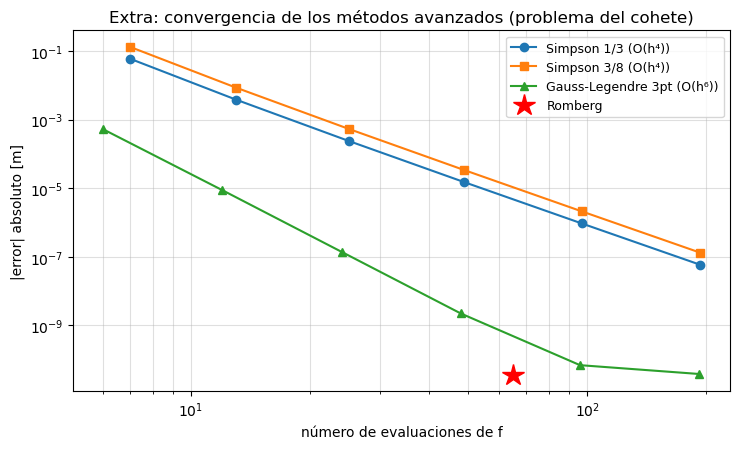

Romberg alcanza error 3.6e-11 con 65 evaluaciones.
Simpson 1/3 con 193 evaluaciones queda en 5.9e-08.

Conclusión: para un integrando suave como éste, Romberg (trapecio + Richardson) y la
cuadratura de Gauss son las más eficientes: precisión de máquina con decenas de evaluaciones;
las reglas de Newton-Cotes compuestas (1/3 y 3/8) convergen igual de bien pero necesitan
más puntos por su orden menor (O(h⁴) vs la convergencia espectacular de la extrapolación).


In [5]:
# Comparación de convergencia: error vs número de evaluaciones de f
ns = [6, 12, 24, 48, 96, 192]
datos = {'Simpson 1/3': [], 'Simpson 3/8': [], 'Gauss 3-pt': []}
evals = {'Simpson 1/3': [], 'Simpson 3/8': [], 'Gauss 3-pt': []}
for n in ns:
    h = (tf - t0)/n
    t = t0 + h*np.arange(n + 1)
    pesos = np.ones(n + 1); pesos[1:-1:2] = 4; pesos[2:-2:2] = 2
    datos['Simpson 1/3'].append(abs(h/3*np.sum(pesos*f(t)) - I_exacta)); evals['Simpson 1/3'].append(n + 1)
    if n % 3 == 0:
        datos['Simpson 3/8'].append(abs(simpson_38(f, t0, tf, n) - I_exacta)); evals['Simpson 3/8'].append(n + 1)
    ng = n//3 if n >= 3 else 1
    datos['Gauss 3-pt'].append(abs(gauss_legendre_compuesta(f, t0, tf, max(ng, 1)) - I_exacta))
    evals['Gauss 3-pt'].append(3*max(ng, 1))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.loglog(evals['Simpson 1/3'], datos['Simpson 1/3'], 'o-', label='Simpson 1/3 (O(h⁴))')
ax.loglog(evals['Simpson 3/8'], datos['Simpson 3/8'], 's-', label='Simpson 3/8 (O(h⁴))')
ax.loglog(evals['Gauss 3-pt'], datos['Gauss 3-pt'], '^-', label='Gauss-Legendre 3pt (O(h⁶))')
ax.loglog([neval_rom], [abs(I_rom - I_exacta)], 'r*', ms=16, label='Romberg')
ax.set_xlabel('número de evaluaciones de f'); ax.set_ylabel('|error| absoluto [m]')
ax.set_title('Extra: convergencia de los métodos avanzados (problema del cohete)')
ax.grid(alpha=0.4, which='both'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"Romberg alcanza error {abs(I_rom - I_exacta):.1e} con {neval_rom} evaluaciones.")
print(f"Simpson 1/3 con 193 evaluaciones queda en {datos['Simpson 1/3'][-1]:.1e}.")
print("\nConclusión: para un integrando suave como éste, Romberg (trapecio + Richardson) y la")
print("cuadratura de Gauss son las más eficientes: precisión de máquina con decenas de evaluaciones;")
print("las reglas de Newton-Cotes compuestas (1/3 y 3/8) convergen igual de bien pero necesitan")
print("más puntos por su orden menor (O(h⁴) vs la convergencia espectacular de la extrapolación).")